# DLBS Mini-Challenge: Object Detection im Eishockey

Autor: Silas Tschopp

**Aufgabe:** Auf Einzelbildern aus Eishockeyspielen werden Spieler (`player`), Torhüter (`goalie`), Schiedsrichter (`referee`) und Tore (`goal`) mit einem Object Detector lokalisiert und klassifiziert.

**Hypothesen (aus dem Proposal)**
- **H1:** Der AP50 der Klasse `referee` liegt auf dem Testset mindestens 5 Prozentpunkte unter dem der Klasse `player` (Mittel über drei Seeds).
- **H2:** `referee` ist unter den vier Klassen die mit dem tiefsten AP50.

**Kapitel**
0. Setup
1. Dateninspektion
2. Gruppen-Split
3. Baseline (COCO-Referenz, yolo26n)
4. Overfit
5. Regularize
6. Tune
7. Ergebnisse und Hypothesenprüfung

In jedem Kapitel wird mit AP50 pro Klasse, mAP50–95 und Konfusionsmatrix ausgewertet. Jedes Kapitel endet mit einer kurzen Diskussion (2–3 Sätze).

## 0 Setup

Die Zelle prüft die Umgebung (Env `dlbs-mc`): PyTorch muss als CUDA-Build laufen und die GPU (RTX 4050 Laptop, 6 GB) sehen, sonst würde das Training auf der CPU laufen. Hier stehen auch die gemeinsamen Konstanten (Seeds, Epochen, Pfade, Augmentation aus), damit sie nur an einer Stelle definiert sind. Die Ultralytics-Version wird ausgegeben, damit die Ergebnisse reproduzierbar sind.

In [1]:
import os
os.environ["PIN_MEMORY"] = "False"

import sys, pathlib, shutil
from pathlib import Path
sys.path.append(str(pathlib.Path("..").resolve()))

import pandas as pd
import matplotlib.pyplot as plt
import torch
import ultralytics
from ultralytics import YOLO

from src.splits import SPLITS

SEED = 42
TRAIN_SEEDS = [42, 43, 44]
EPOCHS = 100
DATA_DIR = Path("..") / "data" / "hockey_without_puck"
MODELS_DIR = Path("..") / "models"
OUTPUT_DIR = Path("..") / "outputs"

NO_AUGMENTATION = dict(
    hsv_h=0.0, hsv_s=0.0, hsv_v=0.0,
    translate=0.0, scale=0.0, fliplr=0.0,
    mosaic=0.0, close_mosaic=0, erasing=0.0,
    auto_augment=None,
)

print("torch:", torch.__version__)
print("CUDA verfügbar:", torch.cuda.is_available())
print("GPU:", torch.cuda.get_device_name(0) if torch.cuda.is_available() else "keine")
print("ultralytics:", ultralytics.__version__)

torch: 2.15.0+cu132
CUDA verfügbar: True
GPU: NVIDIA GeForce RTX 4050 Laptop GPU
ultralytics: 8.4.208


#### Auswertungsfunktion

`evaluiere` wertet ein gespeichertes Modell auf Valid (oder Test) aus und liefert mAP50-95 sowie AP50 pro Klasse. `tabelle_ueber_seeds` ruft sie für alle drei Seeds auf und berechnet Mittel und Standardabweichung. Beide Funktionen werden in den Kapiteln 3 bis 7 wiederverwendet.

In [2]:
def evaluiere(gewichte, split="val", **kwargs):
    model = YOLO(Path(gewichte).resolve())
    m = model.val(
        data=str(OUTPUT_DIR / "splits" / "data.yaml"),
        split=split, imgsz=640, batch=16, workers=4, device=0,
        verbose=False, **kwargs,
    )
    zeile = {"mAP50-95": m.box.map}
    for klasse, ap50 in zip(m.box.ap_class_index, m.box.ap50):
        zeile[f"AP50 {m.names[klasse]}"] = ap50
    return zeile


def tabelle_ueber_seeds(lauf, split="val"):
    zeilen = {
        seed: evaluiere(OUTPUT_DIR / "runs" / f"{lauf}_s{seed}" / "weights" / "best.pt", split, plots=False)
        for seed in TRAIN_SEEDS
    }
    df = pd.DataFrame(zeilen).T
    df.index.name = "seed"
    df.loc["Mittel"] = df.mean()
    df.loc["Std"] = df.iloc[:len(TRAIN_SEEDS)].std()
    return df.round(3)

## 1 Dateninspektion

Ziel dieser Phase ist es, die Daten zu verstehen, bevor trainiert wird: Wie sind die Klassen verteilt, wie gross sind die Objekte, und aus welchen Quellvideos stammen die Bilder? Die Ergebnisse begründen den Gruppen-Split (Kapitel 2) und die Wahl der Metriken.

Datensatz: Roboflow `hockey_without_puck` (YOLOv8-Format), 1'652 Bilder nach Entfernen von sechs Bildern ohne Annotation. Die mitgelieferte Aufteilung ist Train 1'242, Valid 216, Test 194.

### 1.1 Labels einlesen und Quellvideos bestimmen

Alle Labeldateien werden in eine Tabelle `boxes` (eine Zeile pro Box) eingelesen. Die YOLO-Labels enthalten pro Box die Klasse sowie Mittelpunkt, Breite und Höhe, normiert auf die Bildgrösse. Die Klassennamen kommen aus `data.yaml`.

Der Code dafür liegt in `src/splits.py`. Die Funktion `video_id()` bestimmt aus dem Dateinamen die **Quellvideo-Gruppe**. Dazu werden der Roboflow-Hash (`.rf.<hash>`), die Endung und die Frame-Nummer entfernt. Screenshots mit Zeitstempel werden nach Datum zusammengefasst, Dateien ohne erkennbaren Namen bilden die Gruppe `png_unbenannt`. Die sechs Clips `VAN_NJD_HI_v2-<Zeitstempel>` werden zu einer Gruppe zusammengefasst, weil alle geprüften Clips dasselbe Spiel zeigen (siehe Kapitel 2). Die Gruppierung ist eine Heuristik: Die grossen Gruppen (z. B. `VAN_NJD_HI_v2-…`, `InShot_…`) sind echte Videos, kleine Gruppen wie `ncaa`, `avs` oder `frame` sind eher lose Bildserien.

In [3]:
from src.splits import load_class_names, load_boxes

names = load_class_names(DATA_DIR)
print(names)

boxes = load_boxes(DATA_DIR, names)
images = boxes.drop_duplicates("image")[["split", "image", "group"]]
print(f"{len(images)} Bilder, {len(boxes)} Boxen, {images['group'].nunique()} Gruppen")

{0: 'goal', 1: 'goalie', 2: 'player', 3: 'referee'}
1652 Bilder, 13985 Boxen, 23 Gruppen


### 1.2 Klassenverteilung

Die Tabelle zeigt die Anzahl Boxen pro Klasse und Split, danach die Klassenanteile pro Split.

**Ergebnis:** `player` macht 77.6 % aller 13'985 Boxen aus, `referee` 9.9 %, `goalie` 6.4 %, `goal` 6.1 %. Die Klassen sind stark unausgeglichen (`player` ist 8- bis 13-mal häufiger). Deshalb wird pro Klasse der AP ausgewertet und nicht die Accuracy.

Die Anteile unterscheiden sich auch zwischen den mitgelieferten Splits, z. B. liegt `goalie` im Train bei 5.9 % und in Valid bei 8.5 %. Ein Vergleich zwischen Splits ist also nur bedingt fair.

split,train,valid,test,total,anteil_%
cls,,,,,
player,8271,1405,1178,10854,77.6
referee,1065,161,154,1380,9.9
goalie,627,160,113,900,6.4
goal,585,155,111,851,6.1


cls,goal,goalie,player,referee
split,,,,
train,5.5,5.9,78.4,10.1
valid,8.2,8.5,74.7,8.6
test,7.1,7.3,75.7,9.9


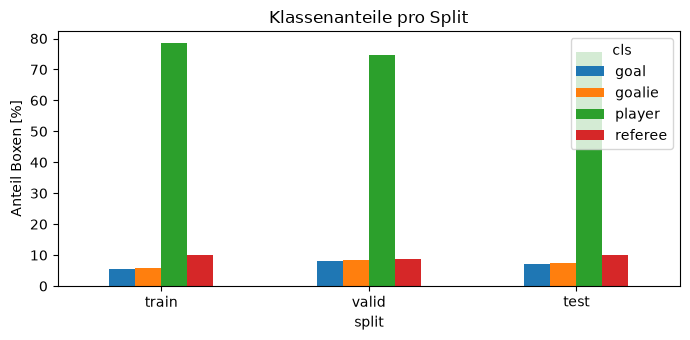

In [4]:
# Klassenverteilung pro Split
counts = pd.crosstab(boxes["cls"], boxes["split"])[SPLITS]
counts["total"] = counts.sum(axis=1)
counts["anteil_%"] = (counts["total"] / counts["total"].sum() * 100).round(1)
display(counts.sort_values("total", ascending=False))

shares = (pd.crosstab(boxes["split"], boxes["cls"], normalize="index") * 100).round(1)
display(shares.loc[SPLITS])

shares.loc[SPLITS].plot(kind="bar", figsize=(7, 3.5), ylabel="Anteil Boxen [%]", title="Klassenanteile pro Split")
plt.xticks(rotation=0); plt.tight_layout(); plt.show()

### 1.3 Quellvideos und Überlappung der Splits (Leakage)

Aufeinanderfolgende Frames desselben Videos sind einander sehr ähnlich. Liegen Frames eines Videos sowohl im Training als auch im Test, kennt das Modell die Szene schon, und die Testleistung wird überschätzt (Data Leakage). Die Tabelle zählt pro Gruppe, in wie vielen Splits sie vorkommt.

**Ergebnis:** Es gibt 23 Gruppen, 14 davon liegen in mehr als einem Split. 1'121 von 1'652 Bildern (68 %) stammen aus solchen Gruppen. Das Video `-10-10-01_12_2024` hat z. B. 18 Bilder im Train, 65 in Valid und 31 im Test.

**Konsequenz:** Der mitgelieferte Split wird nicht verwendet. Stattdessen wird in Kapitel 2 gruppiert nach Quellvideo aufgeteilt, sodass jede Gruppe nur in genau einem Split vorkommt. Da nur wenige Gruppen gross sind (die grösste hat 599 Bilder), lässt sich 70/15/15 nur näherungsweise erreichen.

In [5]:
# Quellvideos / Bildserien und Überlappung der Splits (Leakage-Evidenz)
group_split = pd.crosstab(images["group"], images["split"])[SPLITS]
group_split["total"] = group_split.sum(axis=1)
group_split["in_mehreren_splits"] = (group_split[SPLITS] > 0).sum(axis=1) > 1
display(group_split.sort_values("total", ascending=False))

leak_imgs = group_split.loc[group_split["in_mehreren_splits"], "total"].sum()
print(f"Gruppen: {len(group_split)}; davon in mehreren Splits: {group_split['in_mehreren_splits'].sum()}")
print(f"Bilder aus Gruppen, die über mehrere Splits verteilt sind: {leak_imgs} von {len(images)} ({leak_imgs/len(images):.0%})")

split,train,valid,test,total,in_mehreren_splits
group,,,,,
VAN_NJD_HI_v2,438,72,89,599,True
-13-13-30_11_2024_mp4,162,1,0,163,True
InShot_20250113_230703821_mp4,139,0,0,139,False
7948500339312_mp4,138,0,0,138,False
png_unbenannt,120,0,0,120,False
-10-10-01_12_2024_mp4,18,65,31,114,True
-Power-Ma-hines-01_08_2024_mp4,111,0,0,111,False
-16-16-01_12_2024_mp4,0,7,49,56,True
frame,37,12,4,53,True


Gruppen: 23; davon in mehreren Splits: 14
Bilder aus Gruppen, die über mehrere Splits verteilt sind: 1121 von 1652 (68%)


### 1.4 Boxgrössen

Die Boxfläche wird relativ zur Bildfläche berechnet (Breite × Höhe, beide normiert) und pro Klasse zusammengefasst. Die y-Achse im Boxplot ist logarithmisch, weil sich die Werte über mehrere Grössenordnungen erstrecken.

**Ergebnis:** Der Median liegt bei `player` bei etwa 1.4 %, bei `goal` bei 1.8 %, bei `goalie` bei 1.0 % und bei `referee` bei 0.95 % der Bildfläche. Die Objekte sind klein, am kleinsten sind Schiedsrichter und Torhüter. Das spricht dafür, dass kleine Objekte schwer zu erkennen sind, und passt zu H1 und H2. Es ist aber kein Beleg dafür: Die Hypothesen werden erst mit dem AP50 auf dem Testset geprüft.

           count     min     25%     50%     75%     max
cls                                                     
goal       851.0  0.0010  0.0094  0.0179  0.0314  0.3304
goalie     900.0  0.0007  0.0055  0.0104  0.0176  0.3463
player   10854.0  0.0000  0.0068  0.0136  0.0246  0.8071
referee   1380.0  0.0004  0.0051  0.0095  0.0171  0.3903


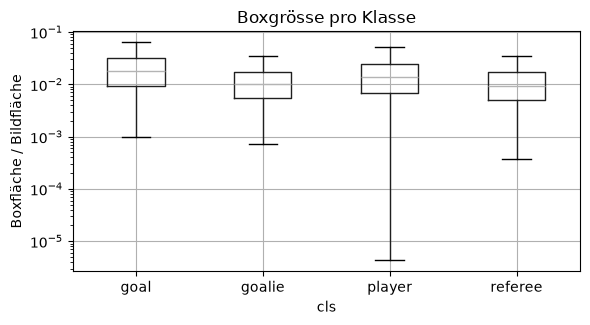

In [6]:
# Boxgrössen (relativ zur Bildfläche) pro Klasse
boxes["area"] = boxes["w"] * boxes["h"]
print(boxes.groupby("cls")["area"].describe()[["count", "min", "25%", "50%", "75%", "max"]].round(4))

boxes.boxplot(column="area", by="cls", figsize=(6, 3.5), showfliers=False)
plt.yscale("log"); plt.ylabel("Boxfläche / Bildfläche"); plt.suptitle(""); plt.title("Boxgrösse pro Klasse")
plt.tight_layout(); plt.show()

### 1.5 Beispielbilder

Vier zufällige Bilder mit den Ground-Truth-Boxen (Farbe = Klasse). Die Stichprobe dient dazu, Annotationen und Bildqualität durchzusehen (Perspektive, Auflösung, verdeckte Spieler, Überlagerungen wie Spielstand).

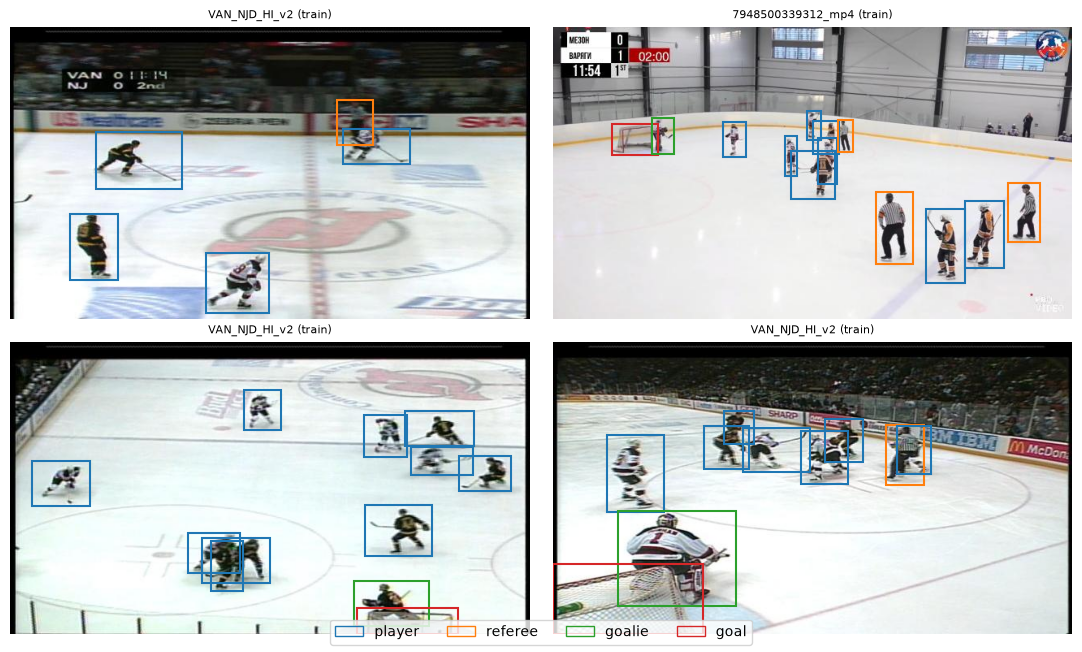

In [7]:
# Beispielbilder mit Ground-Truth-Boxen
from PIL import Image
import matplotlib.patches as patches

colors = {"player": "tab:blue", "referee": "tab:orange", "goalie": "tab:green", "goal": "tab:red"}
sample = images.sample(4, random_state=0)

fig, axes = plt.subplots(2, 2, figsize=(11, 6.5))
for ax, (_, row) in zip(axes.ravel(), sample.iterrows()):
    im = Image.open(DATA_DIR / row["split"] / "images" / row["image"])
    W, H = im.size
    ax.imshow(im); ax.axis("off"); ax.set_title(f"{row['group']} ({row['split']})", fontsize=8)
    for _, b in boxes[boxes["image"] == row["image"]].iterrows():
        ax.add_patch(patches.Rectangle(((b.x - b.w/2) * W, (b.y - b.h/2) * H), b.w * W, b.h * H,
                                       fill=False, edgecolor=colors[b.cls], linewidth=1.5))
handles = [patches.Patch(edgecolor=c, fill=False, label=k) for k, c in colors.items()]
fig.legend(handles=handles, loc="lower center", ncol=4)
plt.tight_layout(); plt.show()

### 1.6 Diskussion Dateninspektion

Der Datensatz enthält 1'652 Bilder mit 13'985 Boxen aus 23 Quellgruppen und ist stark unausgewogen: `player` macht 77.6 % der Boxen aus, `referee` 9.9 %, `goalie` 6.4 % und `goal` 6.1 %. Die seltenen Klassen sind zudem klein (mediane Boxfläche von `referee` und `goalie` rund 1 % der Bildfläche, `player` 1.4 %), weshalb Accuracy ungeeignet ist und AP50 pro Klasse ausgewertet wird [[Lon](https://arxiv.org/abs/2108.02497)]. Die mitgelieferte Aufteilung ist nicht brauchbar, weil 68 % der Bilder aus Quellen stammen, die über mehrere Splits verteilt sind. Deshalb folgt in Kapitel 2 ein gruppenbasierter Split.

## 2 Gruppen-Split

**Warum:** Frames desselben Videos sind sich sehr ähnlich. Der mitgelieferte Split verteilt sie auf Train, Valid und Test (Kapitel 1.3), das Testset ist dann nicht unabhängig und die Testleistung wird überschätzt. Das Modell soll aber auf Bildern funktionieren, die es noch nie gesehen hat. Deshalb wird gruppiert nach Quellvideo aufgeteilt, ungefähr 70/15/15, und die Klassenanteile werden möglichst ähnlich gehalten.

**Was gilt als Gruppe?** Der Dateiname verrät das Quellvideo. Beim Ansehen von Beispielbildern fiel auf, dass die sechs Clips `VAN_NJD_HI_v2-<Zeitstempel>` alle dasselbe Spiel zeigen (gleiche Halle, gleiche Trikots, gleiche Spielstandanzeige VAN–NJ). Würde jeder Clip eine eigene Gruppe bilden, läge ein Clip im Test und die anderen Clips desselben Spiels im Training, das Modell würde Halle und Trikots schon kennen. Deshalb ist das Spiel die Gruppe (599 Bilder, 36 % aller Bilder).

Der Code liegt in `src/splits.py` (`make_group_split`, `write_split_files`), das Notebook zeigt den Aufruf und die Kontrollen.

**Vorgehen:**
1. Die grosse Spielgruppe ist für Valid oder Test zu gross und kommt komplett ins Training.
2. Die übrigen Gruppen werden 20'000-mal zufällig gemischt und der Reihe nach zuerst dem Test, dann der Validierung zugewiesen, bis jede Menge etwa 15 % der Bilder enthält. Der Rest gehört zum Training.
3. Bewertet wird jede Zuweisung nur nach der Qualität des Splits, ohne Modell: Abweichung der Grössen von Valid und Test vom Soll (15 %) plus Abweichung der Klassenanteile (Anteil der Boxen) in Valid und Test vom Gesamtanteil. Zuweisungen, in denen eine einzelne Gruppe mehr als die Hälfte des Testsets ausmacht, werden verworfen. Die beste Zuweisung wird verwendet. Das Testset wird dadurch nicht auf ein Modellergebnis optimiert.
4. Die Suche nutzt nur `numpy` mit festem Seed und ist deshalb reproduzierbar. Ein Versuch mit `StratifiedGroupKFold` lieferte auf zwei Rechnern bei gleichem Seed verschiedene Splits (die Bibliotheksversion ändert das Ergebnis) und braucht ein Label pro Bild, obwohl ein Bild mehrere Klassen enthält. Deshalb wird er nicht verwendet.
5. Prüfen: Bilder und Boxen pro Split, Klassenanteile pro Split, Gruppen in mehreren Splits (muss 0 sein), sibling rate (muss 0 sein).
6. Die Splits als `train.txt`, `val.txt` und `test.txt` mit Bildpfaden speichern. Ultralytics liest diese Listen direkt, die Originalordner bleiben unverändert.

**Einschränkung:** Gruppiert wird nach Quellvideo bzw. Spiel, soweit es der Dateiname und die Bilder erkennen lassen. Stichproben von Videos mit ähnlichem Namen (`-10-10-01_12_2024`, `-16-16-01_12_2024`, `-13-13-30_11_2024`, `InShot_20250113…`, `InShot_20250114…`) zeigen verschiedene Hallen und Mannschaften, sie sind also getrennte Spiele. Sie teilen aber Sendergrafiken und Wasserzeichen (z. B. «PRO VIDEO»), das Modell könnte also auch diese Merkmale lernen. Das begrenzt die Aussage auf Bilder mit ähnlicher Bildgestaltung.

In [8]:
from src.splits import make_group_split

SPLIT_SEED = SEED
imgs = make_group_split(boxes, images, seed=SPLIT_SEED)
print(f"Abweichung vom Soll (Grösse und Klassenanteile): {imgs.attrs['abweichung']:.2f}")

Abweichung vom Soll (Grösse und Klassenanteile): 1.29


### 2.1 Prüfen des Splits

In [9]:
boxes_new = boxes.merge(imgs[["image", "split_new"]], on="image")
order = ["train", "valid", "test"]

summary = pd.DataFrame({
    "bilder": imgs["split_new"].value_counts(),
    "boxen": boxes_new["split_new"].value_counts(),
    "gruppen": imgs.groupby("split_new")["group"].nunique(),
}).loc[order]
summary["bilder_%"] = (summary["bilder"] / summary["bilder"].sum() * 100).round(1)
display(summary)

shares_new = (pd.crosstab(boxes_new["split_new"], boxes_new["cls"], normalize="index") * 100).round(1)
display(shares_new.loc[order])

n_splits_per_group = imgs.groupby("group")["split_new"].nunique()
print("Gruppen in mehreren Splits:", int((n_splits_per_group > 1).sum()), "(muss 0 sein)")

# sibling rate: Anteil Testbilder, deren Gruppe auch im Training vorkommt
train_groups = set(imgs.loc[imgs["split_new"] == "train", "group"])
test_imgs = imgs[imgs["split_new"] == "test"]
sibling_rate = test_imgs["group"].isin(train_groups).mean()
print(f"sibling rate (Test): {sibling_rate:.1%} (muss 0 sein)")

,bilder,boxen,gruppen,bilder_%
split_new,,,,
train,1153,9179,10,69.8
valid,249,2599,2,15.1
test,250,2207,11,15.1


cls,goal,goalie,player,referee
split_new,,,,
train,6.1,6.4,77.7,9.8
valid,6.3,6.9,76.5,10.4
test,5.8,6.0,78.7,9.4


Gruppen in mehreren Splits: 0 (muss 0 sein)
sibling rate (Test): 0.0% (muss 0 sein)


### 2.2 Speichern der Splits

In [10]:
from src.splits import write_split_files

SPLIT_DIR = OUTPUT_DIR / "splits"
write_split_files(imgs, DATA_DIR, SPLIT_DIR, names)

In [11]:
print(imgs.groupby(["split_new", "group"]).size())

split_new  group                         
test       15-01-2023-10-VS-10-               13
           19-03-2023-12-VS-11-2011-           6
           2023-05-03                          3
           3-out                              22
           5-out                               8
           IMG_1862_MOV                        1
           frame                              53
           hockey                              1
           ncaa                               21
           png_unbenannt                     120
           videoplayback_mp4                   2
train      -10-10-01_12_2024_mp4             114
           -13-13-30_11_2024_mp4             163
           -16-16-01_12_2024_mp4              56
           1-out                              21
           4-out                              14
           InShot_20250113_230703821_mp4     139
           InShot_20250114_135701340_mp4      11
           VAN_NJD_HI_v2                     599
           avs             

### 2.3 Diskussion Gruppen-Split

Der gruppierte Split liefert 1'153 / 249 / 250 Bilder (69.8 / 15.1 / 15.1 %) aus 10 / 2 / 11 Gruppen, keine Gruppe liegt in mehreren Splits und die sibling rate im Test ist 0 %. Die Klassenanteile sind in allen Splits ähnlich (z. B. `referee` 9.8 / 10.4 / 9.4 %), die Testleistung kann damit ohne Leakage geschätzt werden [[Lon](https://arxiv.org/abs/2108.02497)]. Einschränkend besteht Valid nur aus zwei Spielen, sodass Validierungswerte stark von diesen Spielen abhängen, und das Testset setzt sich aus vielen kleinen, teils losen Bildserien zusammen.

## 3 Baseline

**Ziel:** Eine einfache Referenz festlegen, mit der alle späteren Modelle verglichen werden (Referenz: COCO-Modell ohne Feintuning; Baseline: yolo26n mit Standardparametern auf vier Klassen, 3 Seeds, ohne zusätzliche Augmentation).

### 3.1 COCO-Referenz: erster Test

Bevor trainiert wird, wird das vortrainierte `yolo26n` (COCO, 80 Klassen) ohne Feintuning auf ein **Beispielbild** angewendet (erstes Bild des ursprünglichen Roboflow-Ordners `test`, nicht des eigenen Testsplits). COCO kennt nur die Klasse `person`, nicht aber Spieler, Torhüter, Schiedsrichter oder Tore. Die Zelle zeigt deshalb nur, was ein unveränderter Detektor auf Eishockeybildern liefert.

**Beobachtung (ein Beispielbild, keine Auswertung):** Alle Feldspieler und der Torhüter werden als `person` erkannt, Torhüter und Spieler sind also nicht unterscheidbar. Stock bzw. Schlittschuhe werden teils als `skis` fehlklassifiziert, das Tor wird nicht erkannt und am Rand taucht eine unsichere `person`-Box auf (Konfidenz 0.34).

**Für die spätere Referenz (Kapitel 3):** Spieler, Torhüter und Schiedsrichter werden in den Referenz-Labels zu einer Klasse `person` zusammengefasst, Tore entfallen (COCO hat keine passende Klasse). Die Referenz misst damit nur die Lokalisation von Personen. Sie wird in Abschnitt 3.3 auf Valid berechnet, auf dem Testset folgt sie in Kapitel 7.

In [12]:
img_path = sorted((DATA_DIR / "test" / "images").glob("*.jpg"))[0]

model = YOLO(MODELS_DIR / "yolo26n.pt")   # COCO-Gewichte
print(model.names[0], len(model.names))
r = model.predict(img_path, device=0, conf=0.25)
r[0].show()

person 80

image 1/1 c:\Users\silas\OneDrive\FHNW\07_Semester\DLBS\DLBS_MC\02_Code\notebooks\..\data\hockey_without_puck\test\images\-10-10-01_12_2024_mp4-0024_jpg.rf.2c11ba4805efdd1977a7d6cd12018e46.jpg: 384x640 7 persons, 2 skiss, 13.2ms
Speed: 41.9ms preprocess, 13.2ms inference, 21.0ms postprocess per image at shape (1, 3, 384, 640)


### 3.2 Baseline yolo26n

Die Baseline ist das vortrainierte `yolo26n` (COCO-Gewichte), feingetunt auf den vier Klassen mit den Standardparametern von Ultralytics (Bildgrösse 640, Batchgrösse 16, 100 Epochen) und **ohne Augmentation**. Mosaic, Spiegeln, Farb- und Skalierungsänderungen sind explizit ausgeschaltet, weil die Baseline der Ausgangspunkt für den Vergleich in den späteren Kapiteln ist und nur eine Änderung gleichzeitig vorgenommen werden soll [[Andrej Karpathy](https://karpathy.github.io/2019/04/25/recipe/)].

Trainiert wird mit drei Seeds (42, 43, 44), um die Streuung durch die Zufallsinitialisierung zu messen. Die Seeds gelten nur für das Training, der Gruppen-Split aus Kapitel 2 bleibt für alle Läufe gleich. Ein Lauf wird übersprungen, wenn sein `results.csv` bereits alle Epochen enthält, damit «Restart & Run All» nicht neu trainiert.

Ausgewertet wird das Modell `best.pt` jedes Laufs (Epoche mit der höchsten Ultralytics-Fitness, einer Gewichtung von mAP50 und mAP50-95) auf **Valid**. Das Testset bleibt bis Kapitel 7 unberührt [[M. Lones](https://arxiv.org/abs/2108.02497)]. Die erste Abbildung zeigt Loss und mAP50 aller drei Seeds, die zweite Train- und Valid-Loss pro Seed mit der Epoche von `best.pt`. Die Tabelle darunter enthält AP50 pro Klasse und mAP50-95.

In [13]:
for seed in TRAIN_SEEDS:
    results_path = OUTPUT_DIR / "runs" / f"baseline_s{seed}" / "results.csv"
    if results_path.exists() and len(pd.read_csv(results_path)) == EPOCHS:
        print(f"Training mit seed={seed} übersprungen, da bereits abgeschlossen.")
        continue

    model = YOLO(MODELS_DIR / "yolo26n.pt")
    results = model.train(
        data=str(OUTPUT_DIR / "splits" / "data.yaml"),
        workers=4,
        epochs=EPOCHS,
        imgsz=640,
        batch=16,
        seed=seed,
        device=0,
        project=str((OUTPUT_DIR / "runs").resolve()),
        name=f"baseline_s{seed}",
        exist_ok=True,
        **NO_AUGMENTATION,
    )

Training mit seed=42 übersprungen, da bereits abgeschlossen.
Training mit seed=43 übersprungen, da bereits abgeschlossen.
Training mit seed=44 übersprungen, da bereits abgeschlossen.


#### Plot der Baseline

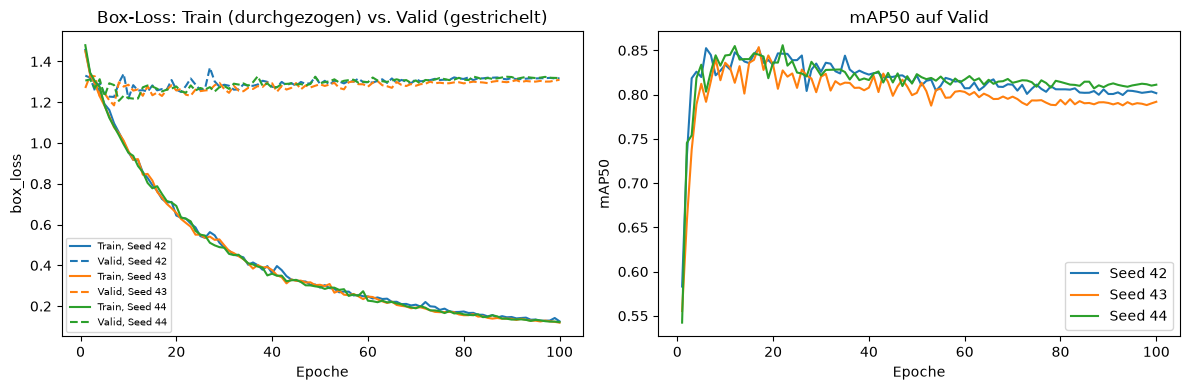

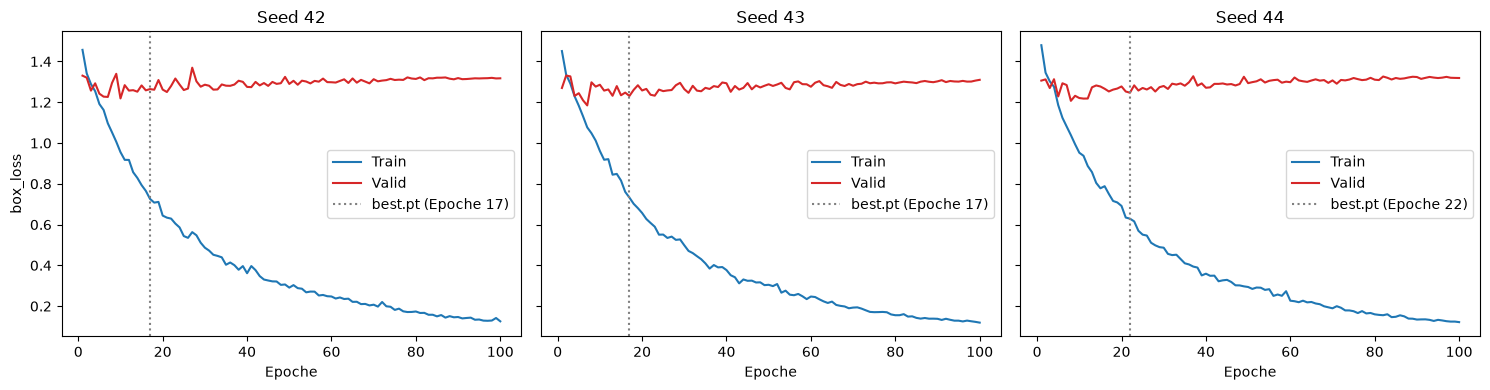

In [14]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
farben = {42: "tab:blue", 43: "tab:orange", 44: "tab:green"}

for seed in TRAIN_SEEDS:
    df = pd.read_csv(OUTPUT_DIR / "runs" / f"baseline_s{seed}" / "results.csv")
    df.columns = df.columns.str.strip()
    axes[0].plot(df["epoch"], df["train/box_loss"], color=farben[seed], label=f"Train, Seed {seed}")
    axes[0].plot(df["epoch"], df["val/box_loss"], color=farben[seed], linestyle="--", label=f"Valid, Seed {seed}")
    axes[1].plot(df["epoch"], df["metrics/mAP50(B)"], color=farben[seed], label=f"Seed {seed}")

axes[0].set_title("Box-Loss: Train (durchgezogen) vs. Valid (gestrichelt)")
axes[0].set_xlabel("Epoche")
axes[0].set_ylabel("box_loss")
axes[0].legend(fontsize=7)

axes[1].set_title("mAP50 auf Valid")
axes[1].set_xlabel("Epoche")
axes[1].set_ylabel("mAP50")
axes[1].legend()

plt.tight_layout()
plt.show()

fig, axes = plt.subplots(1, 3, figsize=(15, 4), sharey=True)

for ax, seed in zip(axes, TRAIN_SEEDS):
    df = pd.read_csv(OUTPUT_DIR / "runs" / f"baseline_s{seed}" / "results.csv")
    df.columns = df.columns.str.strip()
    fitness = 0.1 * df["metrics/mAP50(B)"] + 0.9 * df["metrics/mAP50-95(B)"]
    beste_epoche = df.loc[fitness.idxmax(), "epoch"]

    ax.plot(df["epoch"], df["train/box_loss"], color="tab:blue", label="Train")
    ax.plot(df["epoch"], df["val/box_loss"], color="tab:red", label="Valid")
    ax.axvline(beste_epoche, color="gray", linestyle=":", label=f"best.pt (Epoche {int(beste_epoche)})")
    ax.set_title(f"Seed {seed}")
    ax.set_xlabel("Epoche")
    ax.legend()

axes[0].set_ylabel("box_loss")
plt.tight_layout()
plt.show()

#### Validierung der Baseline

In [15]:
baseline_val = tabelle_ueber_seeds("baseline")
baseline_val

Ultralytics 8.4.208  Python-3.12.16 torch-2.15.0+cu132 CUDA:0 (NVIDIA GeForce RTX 4050 Laptop GPU, 6140MiB)
YOLO26n summary (fused): 121 layers, 2,390,464 parameters, 0 gradients, 5.4 GFLOPs
val: Fast image access  (ping: 0.2±0.1 ms, read: 192.9±41.8 MB/s, size: 24.9 KB)
val: Scanning C:\Users\silas\OneDrive\FHNW\07_Semester\DLBS\DLBS_MC\02_Code\data\hockey_without_puck\train\labels.cache... 249 images, 0 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 249/249  0.0s
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 16/16 1.1it/s 15.1s0.1s
                   all        249       2599      0.897      0.761      0.853      0.551
Speed: 0.8ms preprocess, 3.3ms inference, 0.0ms loss, 1.7ms postprocess per image
Ultralytics 8.4.208  Python-3.12.16 torch-2.15.0+cu132 CUDA:0 (NVIDIA GeForce RTX 4050 Laptop GPU, 6140MiB)
YOLO26n summary (fused): 121 layers, 2,390,464 parameters, 0 gradients, 5.4 GFLOPs
val: Fast image access  (ping: 0.2±0.0 ms

,mAP50-95,AP50 goal,AP50 goalie,AP50 player,AP50 referee
seed,,,,,
42,0.551,0.929,0.775,0.921,0.787
43,0.543,0.935,0.794,0.906,0.775
44,0.550,0.924,0.794,0.912,0.794
Mittel,0.548,0.929,0.788,0.913,0.785
Std,0.005,0.006,0.011,0.007,0.010


#### Konfusionsmatrix

Ultralytics 8.4.208  Python-3.12.16 torch-2.15.0+cu132 CUDA:0 (NVIDIA GeForce RTX 4050 Laptop GPU, 6140MiB)
YOLO26n summary (fused): 121 layers, 2,390,464 parameters, 0 gradients, 5.4 GFLOPs
val: Fast image access  (ping: 0.2±0.0 ms, read: 146.9±17.2 MB/s, size: 25.0 KB)
val: Scanning C:\Users\silas\OneDrive\FHNW\07_Semester\DLBS\DLBS_MC\02_Code\data\hockey_without_puck\train\labels.cache... 249 images, 0 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 249/249  0.0s
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 16/16 1.3it/s 12.3s0.2s
                   all        249       2599      0.897      0.761      0.853      0.551
Speed: 1.0ms preprocess, 3.8ms inference, 0.0ms loss, 3.0ms postprocess per image
Results saved to C:\Users\silas\OneDrive\FHNW\07_Semester\DLBS\DLBS_MC\02_Code\outputs\runs\baseline_s42_val


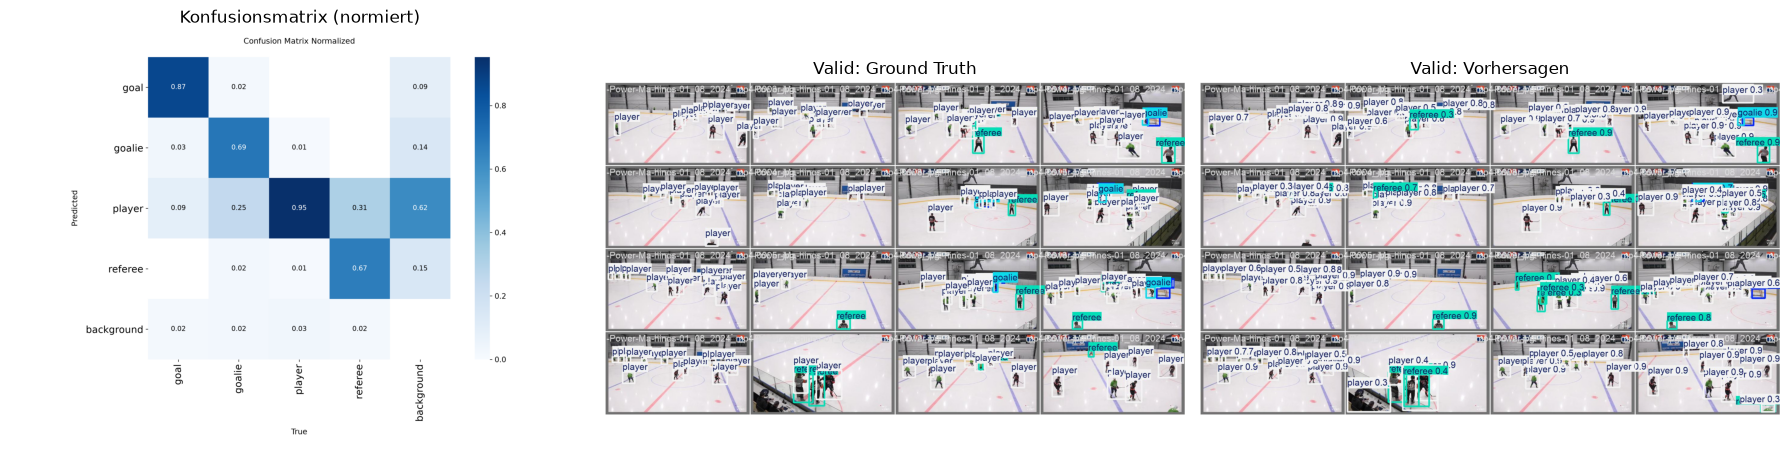

In [16]:
val_dir = (OUTPUT_DIR / "runs" / "baseline_s42_val").resolve()
evaluiere(
    OUTPUT_DIR / "runs" / "baseline_s42" / "weights" / "best.pt",
    plots=True,
    project=str((OUTPUT_DIR / "runs").resolve()),
    name="baseline_s42_val",
    exist_ok=True,
)

fig, axes = plt.subplots(1, 3, figsize=(18, 6))
for ax, datei, titel in zip(
    axes,
    ["confusion_matrix_normalized.png", "val_batch0_labels.jpg", "val_batch0_pred.jpg"],
    ["Konfusionsmatrix (normiert)", "Valid: Ground Truth", "Valid: Vorhersagen"],
):
    ax.imshow(plt.imread(val_dir / datei))
    ax.set_title(titel)
    ax.axis("off")
plt.tight_layout()
plt.show()

### 3.3 COCO-Referenz auf Valid

Als untere Schranke wird das unveränderte `yolo26n` (COCO, ohne Feintuning) auf Valid ausgewertet. COCO kennt nur `person`. In den Referenz-Labels sind deshalb `player`, `goalie` und `referee` zu einer Klasse `person` zusammengefasst, `goal` entfällt. Die Referenz misst damit nur, wie gut Personen lokalisiert werden, und ist **nicht direkt vergleichbar** mit den AP50-Werten pro Klasse der Baseline. Sie zeigt aber, wie viel das Feintuning bringt. Ergebnis: AP50 0.482, mAP50-95 0.168 (Baseline zum Vergleich: AP50 `player` 0.913). Die Auswertung auf dem Testset folgt in Kapitel 7.

In [17]:
COCO_DIR = OUTPUT_DIR / "coco_ref"
namen = names if isinstance(names, dict) else dict(enumerate(names))
goal_id = next(i for i, n in namen.items() if n == "goal")


def baue_person_split(split_datei, split_name):
    """Kopiert die Bilder und schreibt Labels mit einer Klasse `person` (ohne `goal`)."""
    img_dir = COCO_DIR / split_name / "images"
    lbl_dir = COCO_DIR / split_name / "labels"
    img_dir.mkdir(parents=True, exist_ok=True)
    lbl_dir.mkdir(parents=True, exist_ok=True)
    for zeile in Path(split_datei).read_text().splitlines():
        if not zeile.strip():
            continue
        bild = Path(zeile.strip())
        shutil.copy2(bild, img_dir / bild.name)
        label = bild.parent.parent / "labels" / f"{bild.stem}.txt"
        neu = []
        for l in label.read_text().splitlines():
            teile = l.split()
            if int(teile[0]) != goal_id:
                neu.append("0 " + " ".join(teile[1:5]))
        (lbl_dir / f"{bild.stem}.txt").write_text("\n".join(neu))


baue_person_split(OUTPUT_DIR / "splits" / "val.txt", "valid")

(COCO_DIR / "data.yaml").write_text(
    f"path: {COCO_DIR.resolve().as_posix()}\n"
    "train: valid/images\n"
    "val: valid/images\n"
    "names:\n  0: person\n"
)

coco = YOLO(MODELS_DIR / "yolo26n.pt")
m = coco.val(
    data=str(COCO_DIR / "data.yaml"),
    split="val",
    classes=[0],
    imgsz=640, batch=16, workers=4, device=0,
    plots=False, verbose=False,
)
print(f"COCO-Referenz (person) auf Valid: AP50 = {m.box.ap50[0]:.3f}, mAP50-95 = {m.box.map:.3f}")

Ultralytics 8.4.208  Python-3.12.16 torch-2.15.0+cu132 CUDA:0 (NVIDIA GeForce RTX 4050 Laptop GPU, 6140MiB)
YOLO26n summary (fused): 120 layers, 2,408,932 parameters, 0 gradients, 5.5 GFLOPs
WARNING val: Slow image access detected (ping: 0.2±0.0 ms, read: 4.2±0.7 MB/s, size: 24.5 KB). Use local storage instead of remote/mounted storage for better performance. See https://docs.ultralytics.com/guides/model-training-tips
val: Scanning C:\Users\silas\OneDrive\FHNW\07_Semester\DLBS\DLBS_MC\02_Code\outputs\coco_ref\valid\labels... 249 images, 0 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 249/249 606.5it/s 0.4s0.1s
val: New cache created: C:\Users\silas\OneDrive\FHNW\07_Semester\DLBS\DLBS_MC\02_Code\outputs\coco_ref\valid\labels.cache
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 16/16 1.3it/s 12.7s0.1s
                   all        249       2436      0.617      0.583      0.482      0.168
Speed: 0.8ms preprocess, 3.3ms inference, 0

### 3.4 Diskussion Baseline

Die Baseline (yolo26n, ohne Augmentation) erreicht auf Valid einen mAP50-95 von 0.548 (Mittel über drei Seeds, Std 0.005) und ist über die Seeds hinweg stabil. Der unveränderte COCO-Detektor kommt für `person` nur auf AP50 0.482 und mAP50-95 0.168, das Feintuning bringt also deutlich mehr als das Vortraining allein. Der Trainingsloss sinkt über alle 100 Epochen weiter, während Valid-Loss und mAP50 schon nach wenigen Epochen nicht mehr besser werden und danach leicht fallen. Das ist Overfitting und damit der von [[Andrej Karpathy](https://karpathy.github.io/2019/04/25/recipe/)] beschriebene Ausgangspunkt für die Regularisierung (Kapitel 5). Die Klassen `referee` (AP50 0.785) und `goalie` (AP50 0.788) sind am schwächsten, `player` (0.913) und `goal` (0.929) deutlich besser. Der Abstand zwischen `referee` und `goalie` liegt innerhalb der Streuung der Seeds, H2 lässt sich deshalb erst auf dem Testset beurteilen. Alle Werte stammen von Valid, das Testset bleibt bis Kapitel 7 unberührt [[M. Lones](https://arxiv.org/abs/2108.02497)].

## 4 Overfit

**Ziel:** Zeigen, dass das Modell lernen kann, und dokumentieren, wie sich der Trainingsloss verhält, wenn die Komplexität schrittweise steigt (Karpathy: erst Overfitting, dann Regularisierung).

**Vorgehen:**
1. Ein Batch (16 Bilder aus Train), ohne Augmentation und ohne Weight Decay: Der Loss muss gegen null gehen, sonst stimmt etwas an der Pipeline nicht.
2. Volles Trainingsset: entspricht der Baseline aus Kapitel 3 (Trainingsloss sinkt weiter, Valid-Loss steigt).

#### Mini Datensatz

In [18]:
train_boxes = boxes_new[boxes_new["split_new"] == "train"]

ausgewaehlt = []
for klasse in ["referee", "goalie", "goal"]:
    kandidaten = train_boxes.loc[
        (train_boxes["cls"] == klasse) & ~train_boxes["image"].isin(ausgewaehlt), "image"
    ].drop_duplicates()
    ausgewaehlt += list(kandidaten.sample(2, random_state=SEED))

rest = train_boxes["image"].drop_duplicates()
rest = rest[~rest.isin(ausgewaehlt)]
ausgewaehlt += list(rest.sample(16 - len(ausgewaehlt), random_state=SEED))

ein_batch = imgs[imgs["image"].isin(ausgewaehlt)]
mini = pd.concat([ein_batch.assign(split_new="train"), ein_batch.assign(split_new="valid")])
EIN_BATCH_DIR = OUTPUT_DIR / "splits_ein_batch"
write_split_files(mini, DATA_DIR, EIN_BATCH_DIR, names)

print(f"{len(ein_batch)} Bilder")
print(train_boxes[train_boxes["image"].isin(ausgewaehlt)]["cls"].value_counts())

16 Bilder
cls
player     93
referee    12
goalie     11
goal       10
Name: count, dtype: int64


#### Training mit 3 Seeds

In [19]:
EPOCHS_EIN_BATCH = 200

for seed in TRAIN_SEEDS:
    results_path = OUTPUT_DIR / "runs" / f"ein_batch_s{seed}" / "results.csv"
    if results_path.exists() and len(pd.read_csv(results_path)) == EPOCHS_EIN_BATCH:
        print(f"Training mit seed={seed} übersprungen, da bereits abgeschlossen.")
        continue

    model = YOLO(MODELS_DIR / "yolo26n.pt")
    model.train(
        data=str((EIN_BATCH_DIR / "data.yaml").resolve()),
        workers=4,
        epochs=EPOCHS_EIN_BATCH,
        imgsz=640,
        batch=16,
        nbs=16,
        warmup_epochs=0,
        weight_decay=0.0,
        patience=0,
        seed=seed,
        device=0,
        project=str((OUTPUT_DIR / "runs").resolve()),
        name=f"ein_batch_s{seed}",
        exist_ok=True,
        **NO_AUGMENTATION,
    )

New https://pypi.org/project/ultralytics/8.4.218 available  Update with 'pip install -U ultralytics'
Ultralytics 8.4.208  Python-3.12.16 torch-2.15.0+cu132 CUDA:0 (NVIDIA GeForce RTX 4050 Laptop GPU, 6140MiB)
engine\trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=None, batch=16, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=0, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=C:\Users\silas\OneDrive\FHNW\07_Semester\DLBS\DLBS_MC\02_Code\outputs\splits_ein_batch\data.yaml, degrees=0.0, deterministic=True, device=0, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=200, erasing=0.0, exist_ok=True, fliplr=0.0, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.0, hsv_s=0.0, hsv_v=0.0, imgsz=640, iou=None, kobj=1.0, line_width=None, lr0=0.01, lrf=

#### Auswertung

Die Abbildung zeigt Trainingsloss und mAP50 auf den 16 Bildern für drei Seeds. Der zweite Schritt (volles Trainingsset) entspricht der Baseline aus Kapitel 3.

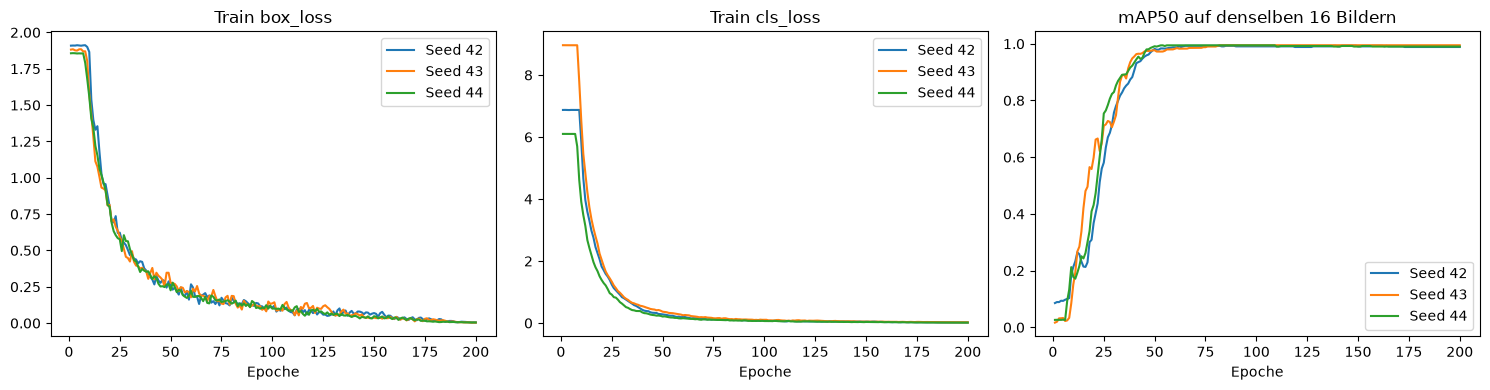

In [20]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
farben = {42: "tab:blue", 43: "tab:orange", 44: "tab:green"}
for seed in TRAIN_SEEDS:
    df = pd.read_csv(OUTPUT_DIR / "runs" / f"ein_batch_s{seed}" / "results.csv")
    df.columns = df.columns.str.strip()
    axes[0].plot(df["epoch"], df["train/box_loss"], color=farben[seed], label=f"Seed {seed}")
    axes[1].plot(df["epoch"], df["train/cls_loss"], color=farben[seed], label=f"Seed {seed}")
    axes[2].plot(df["epoch"], df["metrics/mAP50(B)"], color=farben[seed], label=f"Seed {seed}")

for ax, titel in zip(axes, ["Train box_loss", "Train cls_loss", "mAP50 auf denselben 16 Bildern"]):
    ax.set_title(titel)
    ax.set_xlabel("Epoche")
    ax.legend()
plt.tight_layout()
plt.show()

### Diskussion Overfit

Das Modell kann einen Batch von 16 Bildern vollständig auswendig lernen: Der Trainingsloss geht in allen drei Seeds gegen null (box_loss 0.003–0.005) und der mAP50 auf denselben Bildern erreicht 0.99, die Pipeline mit Labels, Loss und Lernrate funktioniert also [[Andrej Karpathy](https://karpathy.github.io/2019/04/25/recipe/)]. Dafür waren `weight_decay=0`, `nbs=16` und kein Warm-up nötig, damit jeder Batch ein Update auslöst. Der Test sagt nichts über die Generalisierung, diese zeigt erst das volle Trainingsset der Baseline (Abschnitt 3.2), dessen Valid-Loss nach wenigen Epochen steigt.

## 5 Regularize

**Ziel:** Generalisierung verbessern (Augmentation, Early Stopping, Weight Decay), Vergleich über 3 Seeds.

(folgt)

### Diskussion Regularize

(2–3 Sätze.)

## 6 Tune

**Ziel:** Random Search über die Lernrate mit kleinem Budget, ausgehend vom besten Modell.

(folgt)

### Diskussion Tune

(2–3 Sätze.)

## 7 Ergebnisse und Hypothesenprüfung

Tabelle aller Konfigurationen (AP50 pro Klasse, mAP50–95, Mittel ± Standardabweichung über 3 Seeds), Konfusionsmatrix und Prüfung von H1 und H2 auf dem Testset.

(folgt)